**import the dependencies**


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [ ]:
titanic_data = pd.read_csv('/content/train.csv')
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


take the info and size


In [ ]:
titanic_data.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [ ]:
#find null value
titanic_data.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
titanic_data = pd.read_csv('/content/train.csv')
titanic_data = titanic_data.drop(columns = 'Cabin', axis = 1)

In [ ]:
#find null value
titanic_data.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [ ]:
#fill age null values with mean
titanic_data['Age'] = titanic_data['Age'].fillna(titanic_data['Age'].mean())

In [ ]:
#fix embark column
titanic_data['Embarked'] = titanic_data['Embarked'].fillna(titanic_data['Embarked'].mode()[0])

getting some statistical **data**

In [ ]:
titanic_data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.002015,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,29.699118,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
titanic_data['Survived'].value_counts()

,count
Survived,
0,549
1,342


# visulization

In [ ]:
sns.set()

<Axes: xlabel='Survived', ylabel='count'>

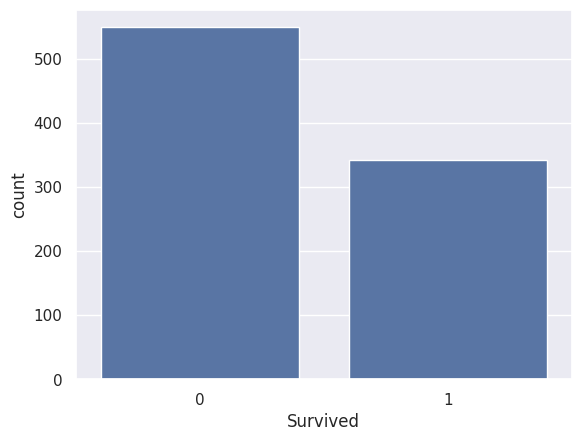

In [ ]:
sns.countplot(x='Survived',data = titanic_data)

<Axes: xlabel='Sex', ylabel='count'>

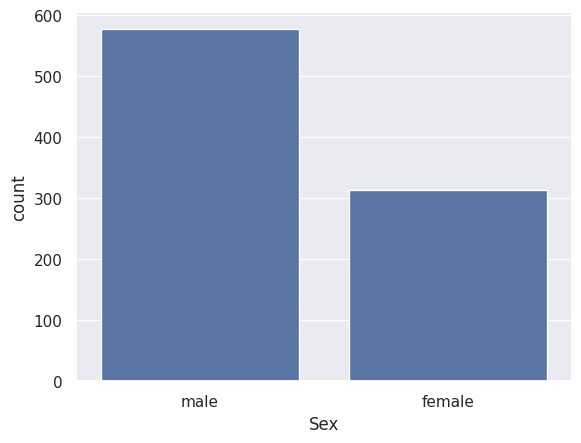

In [ ]:
sns.countplot(x= "Sex",data = titanic_data)

<Axes: xlabel='Sex', ylabel='count'>

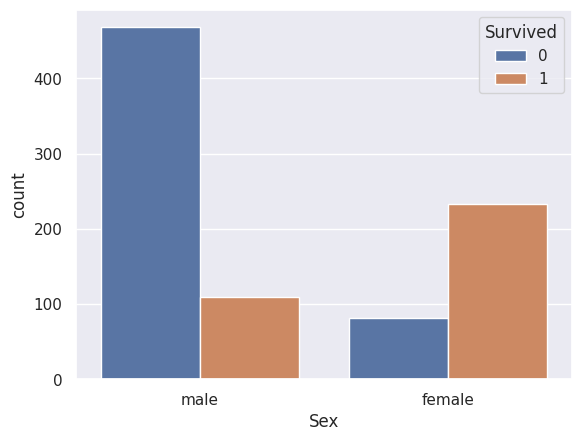

In [ ]:
sns.countplot(x = "Sex",hue = "Survived",data = titanic_data)

<Axes: xlabel='Pclass', ylabel='count'>

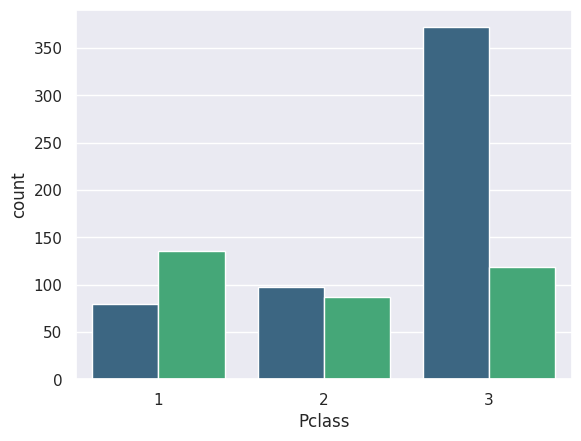

In [ ]:
sns.countplot(x = "Pclass", hue = "Survived", data = titanic_data, palette='viridis', legend=False)

Encoding the categorical column



In [ ]:
titanic_data["Embarked"].value_counts()

,count
Embarked,
S,646
C,168
Q,77


convert catogorical  **column**

In [ ]:
titanic_data.replace({'Sex':{'male':0,'female':1}, 'Embarked':{'S':0,'C':1,'Q':2}}, inplace=True)

/tmp/ipykernel_394/4126089538.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  titanic_data.replace({'Sex':{'male':0,'female':1}, 'Embarked':{'S':0,'C':1,'Q':2}}, inplace=True)


In [ ]:
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,1
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,0
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,0


# separting features and **targets**

In [ ]:
x= titanic_data.drop(columns=['PassengerId','Name','Ticket','Survived'],axis = 1)
y =titanic_data['Survived']

In [ ]:
print(y)

0      0
1      1
2      1
3      1
4      0
      ..
886    0
887    1
888    0
889    1
890    0
Name: Survived, Length: 891, dtype: int64


split the data into training and testin

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2,random_state = 2)

In [ ]:
print(x.shape,x_train.shape,x_test.shape)

(891, 7) (712, 7) (179, 7)


# logistic Regression


In [ ]:
model =  LogisticRegression()

In [ ]:
model.fit(x_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

# Model **evalution**

In [ ]:
#accuracy on train data
x_train_prediction = model.predict(x_train)
print(x_train_prediction)

[0 1 0 0 0 0 0 1 0 0 0 1 0 0 1 0 1 0 0 0 0 0 1 0 0 1 0 0 1 0 1 1 0 0 1 0 1
 0 0 0 0 0 0 1 1 0 0 1 0 1 0 1 0 0 0 0 0 0 1 0 1 0 0 1 1 0 0 1 1 0 1 0 0 1
 0 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 1 0 0 1 0 0 0 1 1 1 0 1 0 0 0 0 0 1 0 0 0
 1 1 0 0 1 0 0 1 0 0 1 0 0 1 0 1 0 1 0 1 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 0
 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 1 0 0 1 0 1 0 1 1 1
 0 0 0 1 0 0 0 1 0 0 1 0 0 0 1 1 0 1 0 0 0 0 0 1 1 0 1 1 1 1 0 0 0 0 0 0 0
 0 1 0 0 1 1 1 0 0 1 0 1 1 1 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 1 0 1 0 1 0 0 0
 0 0 0 0 0 0 1 0 1 0 0 1 0 0 1 0 1 0 1 1 0 0 0 0 1 0 1 0 0 1 0 0 0 1 0 0 0
 0 1 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 1 1 1 0 0 0 1 0 1 0 0 0 0 0 0 1 1 0 1 1
 0 1 1 1 0 0 0 0 0 0 0 0 0 1 0 0 1 1 1 0 1 0 0 0 0 1 1 0 0 0 1 0 1 1 1 0 0
 0 0 1 0 0 0 1 1 0 0 1 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 1 0 1 1 1 0 1 1 0 0 0
 0 1 0 1 0 0 1 1 0 0 0 0 1 0 0 0 0 1 1 0 1 0 1 0 0 0 0 0 1 0 0 0 0 1 1 0 0
 1 0 1 0 0 1 0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 0 1 1 0 1 0 0 1 0 0 0 1 1 0 1 0
 0 0 0 0 1 0 0 1 0 1 1 0 

In [ ]:
training_data_accuracy = accuracy_score(y_train,x_train_prediction)
print('Accuracy score of training data : ', training_data_accuracy)

Accuracy score of training data :  0.8075842696629213


In [ ]:
x_test_prediction = model.predict(x_test)
print(x_test_prediction)

[0 0 1 0 0 0 0 0 0 0 0 1 1 0 0 1 0 0 1 0 1 1 0 1 0 1 1 0 0 0 0 0 0 0 0 1 1
 0 0 0 0 0 1 0 0 1 1 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 1 0 0 0 1 0 1 0
 1 0 0 0 1 0 1 0 0 0 1 1 0 0 1 0 0 0 0 0 0 1 0 1 0 0 1 0 1 1 0 1 1 0 0 0 0
 0 0 0 1 1 0 1 0 0 1 0 0 0 0 0 0 1 0 0 0 0 1 1 0 0 0 0 0 0 1 1 1 1 0 1 0 0
 0 1 0 0 0 0 1 0 0 1 1 0 1 0 0 0 1 1 0 0 1 0 0 1 1 1 0 0 0 0 0]


In [ ]:
test_data_accuracy = accuracy_score(y_test,x_test_prediction)
print('Accuracy score of testing data : ', test_data_accuracy)

Accuracy score of testing data :  0.7821229050279329


### Predictive System for New Data

Now you can use the trained model to predict survival for a new passenger. You will need to input values for the following features:

*   **Pclass**: Passenger Class (1, 2, or 3)
*   **Sex**: Gender (0 for male, 1 for female)
*   **Age**: Age in years
*   **SibSp**: Number of siblings/spouses aboard
*   **Parch**: Number of parents/children aboard
*   **Fare**: Passenger fare
*   **Embarked**: Port of Embarkation (0 for S, 1 for C, 2 for Q)

Enter the values in the code cell below.

In [ ]:
# Take input for a new passenger
print("Enter details for a new passenger:")


pclass_input = int(input("Passenger Class (1, 2, or 3): "))
sex_input = int(input("Sex (0 for male, 1 for female): "))
age_input = float(input("Age: "))
sibsp_input = int(input("Number of siblings/spouses aboard: "))
parch_input = int(input("Number of parents/children aboard: "))
fare_input = float(input("Fare: "))
embarked_input = int(input("Port of Embarkation (0 for S, 1 for C, 2 for Q): "))

# Create a DataFrame for the new input, ensuring column order matches training data
new_data = pd.DataFrame({
    'Pclass': [pclass_input],
    'Sex': [sex_input],
    'Age': [age_input],
    'SibSp': [sibsp_input],
    'Parch': [parch_input],
    'Fare': [fare_input],
    'Embarked': [embarked_input]
})

# Make prediction
new_prediction = model.predict(new_data)

# Output the prediction
if new_prediction[0] == 0:
    print("\nPrediction: The passenger is predicted NOT to survive.")
else:
    print("\nPrediction: The passenger is predicted to survive.")


Enter details for a new passenger:
Passenger Class (1, 2, or 3): 1
Sex (0 for male, 1 for female): 0
Age: 19
Number of siblings/spouses aboard: 1
Number of parents/children aboard: 1
Fare: 700
Port of Embarkation (0 for S, 1 for C, 2 for Q): 2

Prediction: The passenger is predicted to survive.


### 📊 Detailed 10-Slide PowerPoint (PPT) Outline: Titanic Survival Prediction

#### **Slide 1: Title Slide**
*   **Title:** Predicting Survival on the Titanic: A Machine Learning Approach
*   **Subtitle:** Exploratory Data Analysis, Classification Models, and Interactive Predictions
*   **Presenter Name:** [Your Name / Team Name]
*   **Core Objective:** Build a predictive binary classifier to determine passenger survival rates based on demographic and socioeconomic variables.

---

#### **Slide 2: Executive Summary & Project Objectives**
*   **The Problem:** Analyze historical passenger data from the Titanic disaster to predict survival patterns.
*   **Business/Research Value:** Demonstrate classification methodology, data imputation, and features that impact passenger outcomes under emergency conditions.
*   **Key Deliverable:** A robust Logistic Regression classifier predicting whether a given passenger survived (1) or did not survive (0).

---

#### **Slide 3: Data Source & Feature Description**
*   **Dataset Size:** 891 samples, 12 initial columns.
*   **Key Features Explained:**
    *   `Pclass`: Ticket class (1st, 2nd, 3rd as a proxy for socioeconomic status).
    *   `Sex` & `Age`: Demographics.
    *   `SibSp` & `Parch`: Family metrics (Siblings/Spouses & Parents/Children).
    *   `Fare` & `Embarked`: Ticket price and port of boarding (S = Southampton, C = Cherbourg, Q = Queenstown).

---

#### **Slide 4: Data Preprocessing & Cleaning Strategy**
*   **Handling Null Values:**
    *   **Cabin (687 missing):** Column dropped due to a high volume of missing records (~77%).
    *   **Age (177 missing):** Replaced missing entries with the mean age of passengers (~29.7 years).
    *   **Embarked (2 missing):** Filled using the mode ('S' - Southampton).
*   **Target Verification:** Cleaned dataset has no remaining null values across the chosen features.

---

#### **Slide 5: Feature Engineering & Label Encoding**
*   **Converting Text to Numbers:** Machine learning models require numerical matrices.
*   **Transformations Applied:**
    *   `Sex`: Mapped `male` to `0` and `female` to `1`.
    *   `Embarked`: Mapped categorical ports to numeric codes (`S` $\rightarrow$ `0`, `C` $\rightarrow$ `1`, `Q` $\rightarrow$ `2`).
*   **Feature Dropping:** Excluded `PassengerId`, `Name`, and `Ticket` to prevent model overfitting to unique identifier noise.

---

#### **Slide 6: EDA - Demographics and Survival Rates**
*   **Overall Survival Baseline:** **38.4%** of the sample survived (342 out of 891).
*   **The "Women and Children First" Trend:**
    *   Females had a significantly higher survival rate than males.
    *   Over 70% of female passengers survived, compared to under 20% of male passengers.

---

#### **Slide 7: EDA - Socioeconomic Factors & Ticket Class**
*   **Class Disparity (`Pclass`):**
    *   **1st Class:** Highest probability of survival; prioritized during evacuation.
    *   **3rd Class:** The largest group of passengers, but suffered the highest casualty rate.
*   **Inference:** Strong correlation between passenger ticket cost (`Fare` / `Pclass`) and their chance of survival.

---

#### **Slide 8: Model Architecture & Training**
*   **Algorithm Selected:** Logistic Regression (highly interpretable baseline binary classifier).
*   **Data Split:** 80% of data dedicated to training (712 records); 20% reserved for validation (179 records).
*   **Random State:** Initialized with a fixed seed (`random_state=2`) to guarantee reproducible split boundaries.

---

#### **Slide 9: Model Performance & Evaluation**
*   **Metric:** Classification Accuracy.
*   **Training Accuracy:** **80.76%**
*   **Testing Accuracy:** **78.21%**
*   **Performance Evaluation:** Strong performance for a baseline linear classifier. The minor gap (~2.5%) between training and validation scores indicates that the model generalizes well and does not suffer from high variance (overfitting).

---

#### **Slide 10: Real-Time Predictive System & Conclusion**
*   **Interactive Framework:** Designed a custom interface where new passenger details can be mapped directly into the model for inference.
*   **Example Outcome:** A 19-year-old male traveling in 1st class with a high fare (700) is predicted **to survive** due to class and fare prioritization overrides.
*   **Next Steps for Improvement:**
    1.  Test non-linear tree-based models (e.g., Random Forest, XGBoost).
    2.  Extract titles (e.g., Mr., Mrs., Miss.) from passenger names as a proxy for social status.